# 03 - Train and compare the transistor models (Part A, step 2)

Self-contained notebook, built up in parts:

1. **Harness:** data split, source/drain canonicalisation, target transforms, physics features and the metrics used everywhere else, each with a check.
2. **Baseline models (this part):** polynomial ridge regression and gradient boosting, each tried with and without the Vds-aware target and the physics features.
3. Neural models (MLP and residual MLP) and the comparison table (4 model types x 4 cases, validation R2, median and 95th-percentile error).
4. Selection of the best model per case, test-set results, predicted-vs-SPICE plots and the four saved model files.

One model per case (NMOS ON, NMOS OFF, PMOS ON, PMOS OFF), each predicting the four terminal currents `id, ig, is, ib`.
Model families to compare: residual MLP, plain MLP, gradient boosting (LightGBM) and polynomial ridge regression (plus extra trees as an optional fifth).
Only the CSV files in `data/` are needed (the symmetry check in section 2 also uses ngspice and the model file, and is skipped if they are missing).

In [1]:
import re
import shutil
import subprocess
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data"
RESULT_DIR = ROOT / "results"
MODEL_DIR = ROOT / "models"
MODEL_FILE = ROOT / "Model Files-20261105" / "models" / "16nm_HP.pm"
LDIFF = 32e-9                               # AD = AS = W * LDIFF, as in the datasets

CASES = {"nmos_on": "nmos", "nmos_off": "nmos", "pmos_on": "pmos", "pmos_off": "pmos"}
FEATS = ["vdd", "temp", "w", "vd", "vs", "vg", "vb", "vth0", "toxe", "ndep", "u0", "xj"]
TERMS = ["id", "ig", "is", "ib"]            # terminal currents flowing into the device
SPLIT = (0.70, 0.15, 0.15)                  # train / validation / test
SPLIT_SEED = 20261105
I0 = 1e-16                                  # scale of the signed-log transform [A]
REL_FLOOR = 1e-15                           # relative errors are only meaningful above the solver floor [A]
SMALL_VDS = 5e-3                            # |Vds| below this is the "small-Vds" region [V]
KB_Q = 8.617333262e-5                       # k/q [V/K]

data = {c: pd.read_csv(DATA_DIR / f"{c}.csv") for c in CASES}
{c: d.shape for c, d in data.items()}

{'nmos_on': (10000, 16),
 'nmos_off': (10000, 16),
 'pmos_on': (10000, 16),
 'pmos_off': (10000, 16)}

## 1. Split
Random 70 / 15 / 15 split with a fixed seed: 7,000 train, 1,500 validation, 1,500 test rows per case. Models are compared on the validation split;
the test split is only used once, for the chosen model.

In [2]:
def split_indices(n, seed=SPLIT_SEED):
    perm = np.random.default_rng(seed).permutation(n)
    n_tr, n_va = int(SPLIT[0] * n), int(SPLIT[1] * n)
    return perm[:n_tr], perm[n_tr:n_tr + n_va], perm[n_tr + n_va:]


splits = {c: split_indices(len(d)) for c, d in data.items()}
tr, va, te = splits["nmos_on"]
print("rows per split:", len(tr), len(va), len(te), "| disjoint:", len(set(tr) | set(va) | set(te)) == len(data["nmos_on"]))

rows per split: 7000 1500 1500 | disjoint: True


## 2. Source/drain canonicalisation
The device is symmetric in drain and source (the netlists use `AD = AS`), so swapping the two terminals gives the same device: `id` and `is` trade places and `ig`, `ib` are unchanged.
Drain and source are drawn independently, so half the samples sit in each orientation. Mapping every sample to one orientation (**Vds >= 0 for NMOS, Vsd >= 0 for PMOS**) fixes the sign of `id` and `is` per case, and removes the sign change at Vd = Vs from the learning problem.
The check below compares real SPICE results for the two orientations (nominal process, W = 32 nm).

In [3]:
def canonicalize(df, device):
    """Swap drain and source where needed so that Vds >= 0 (NMOS) or Vsd >= 0 (PMOS); id and is swap with them."""
    d = df.copy()
    swap = (d["vd"] < d["vs"]) if device == "nmos" else (d["vd"] > d["vs"])
    d.loc[swap, ["vd", "vs"]] = d.loc[swap, ["vs", "vd"]].to_numpy()
    d.loc[swap, ["id", "is"]] = d.loc[swap, ["is", "id"]].to_numpy()
    return d, swap


canon, swapped = {}, {}
for c, dev in CASES.items():
    canon[c], swapped[c] = canonicalize(data[c], dev)
print("fraction of rows swapped:", {c: round(float(s.mean()), 3) for c, s in swapped.items()})

# canonicalising twice changes nothing, and the orientation is now fixed
again, _ = canonicalize(canon["nmos_on"], "nmos")
print("idempotent:", bool(again.equals(canon["nmos_on"])))

sign = pd.DataFrame({c: {t: f"{(d.iloc[splits[c][0]][t] > 0).mean():.3f}" for t in TERMS} for c, d in canon.items()})
print("fraction of positive values after canonicalisation (training rows only):")
sign

fraction of rows swapped: {'nmos_on': 0.505, 'nmos_off': 0.498, 'pmos_on': 0.5, 'pmos_off': 0.498}
idempotent: True
fraction of positive values after canonicalisation (training rows only):


,nmos_on,nmos_off,pmos_on,pmos_off
id,1.000,1.000,0.000,0.000
ig,1.000,0.000,0.000,0.912
is,0.000,0.571,1.000,0.650
ib,0.000,0.002,1.000,0.733


After canonicalisation the signs of all four currents are fixed in the ON cases. In the OFF cases `is`, `ib` and (PMOS) `ig` still change sign: they are small and set by the balance of the channel, gate and body components. The signed-log target is therefore still needed.

In [4]:
SPICE_OPTIONS = ".options gmin=1e-18 abstol=1e-18 reltol=1e-6 vntol=1e-9"
VDD = 0.9
BIAS = {  # (vg, vb) per case
    "nmos_on": (VDD, 0.0), "nmos_off": (0.0, 0.0), "pmos_on": (0.0, VDD), "pmos_off": (VDD, VDD)}


def run_ngspice(netlist, name="symmetry.cir"):
    build = ROOT / "build"
    build.mkdir(exist_ok=True)
    shutil.copyfile(MODEL_FILE, build / MODEL_FILE.name)
    (build / name).write_text(netlist, newline="\n")
    if shutil.which("ngspice"):
        return subprocess.run(["ngspice", "-b", name], cwd=build, capture_output=True, text=True).stdout
    p = build.resolve()
    wsl = "/mnt/" + p.drive.rstrip(":").lower() + "/" + "/".join(p.parts[1:])
    r = subprocess.run(["wsl", "-e", "bash", "-c", f"cd '{wsl}' && ngspice -b {name} 2>/dev/null"], capture_output=True, text=True)
    return r.stdout.replace("\x00", "")


def symmetry_netlist():
    lines = ["* drain/source symmetry check", f".include {MODEL_FILE.name}", SPICE_OPTIONS]
    runs = []
    for c, dev in CASES.items():
        vg, vb = BIAS[c]
        for k, (vd, vs) in enumerate([(0.5, 0.2), (0.2, 0.5)]):
            t = f"{c}_{k}"
            w = 32e-9
            lines.append(f"M{t} d{t} g{t} s{t} b{t} {dev} W={w:.6g} L=16n AD={w * LDIFF:.6g} AS={w * LDIFF:.6g}")
            lines += [f"Vd{t} d{t} 0 {vd}", f"Vg{t} g{t} 0 {vg}", f"Vs{t} s{t} 0 {vs}", f"Vb{t} b{t} 0 {vb}"]
            runs.append(t)
    lines += [".control", "set numdgt = 15", "set temp = 27", "op"]
    lines += ["print " + " ".join(f"i(v{x}{t})" for x in "dgsb") for t in runs]
    lines += [".endc", ".end", ""]
    return "\n".join(lines), runs


try:
    text, runs = symmetry_netlist()
    out = run_ngspice(text)
    vals = [-float(v) for v in re.findall(r"^i\(v[dgsb]\w*\) = (\S+)$", out, re.M)]
    assert len(vals) == 4 * len(runs), "ngspice did not return all results"
    cur = {t: vals[4 * k:4 * k + 4] for k, t in enumerate(runs)}
    rows = []
    for c in CASES:
        a, b = cur[f"{c}_0"], cur[f"{c}_1"]            # (id, ig, is, ib) before and after swapping drain and source
        rows.append(dict(case=c, id_vs_is_swapped=abs(a[0] - b[2]) / abs(a[0]), is_vs_id_swapped=abs(a[2] - b[0]) / abs(a[2]),
                         ig=abs(a[1] - b[1]) / abs(a[1]), ib=abs(a[3] - b[3]) / abs(a[3])))
    sym = pd.DataFrame(rows).set_index("case")
    print("relative mismatch between the two orientations (0 = perfectly symmetric):")
    display(sym.style.format("{:.1e}"))
except Exception as e:                                  # ngspice or the model file not available
    print("symmetry check skipped:", e)

relative mismatch between the two orientations (0 = perfectly symmetric):


,id_vs_is_swapped,is_vs_id_swapped,ig,ib
case,,,,
nmos_on,1.5e-14,1.7e-14,0.0e+00,1.8e-10
nmos_off,5.3e-08,7.0e-06,0.0e+00,1.9e-05
pmos_on,1.2e-13,1.2e-13,2.7e-15,0.0e+00
pmos_off,1.4e-03,1.7e-04,0.0e+00,0.0e+00


## 3. Target transforms
The currents span about 11 decades and (before canonicalisation) change sign, so the models are trained on a transformed target.

* **Signed log:** `y = arcsinh(I / I0)` with `I0 = 1e-16 A`. For `|I| >> I0` it equals `ln(2|I|/I0)`, so an error in `y` is a relative error in `I`; it is linear near zero and keeps the sign.
* **Vds-aware factor (id and is only):** the BSIM sub-threshold current carries the factor `1 - exp(-Vds / V_therm)` (lecture slide 10), with `V_therm = kT/q`. At `|Vds|` of 1 uV to a few mV, where the ON devices sit inside a gate, the current is proportional to `Vds` and crosses zero. Dividing by the factor leaves a smooth quantity that does not vanish at `Vds -> 0`:
  `y = arcsinh((I / factor) / I0)`, inverted by `I = I0 sinh(y) * factor`.

**Caveat (checked below and on the validation rows):** the factor only helps where the current really is proportional to Vds at small Vds. In the ON cases the channel is in its linear region, so it should be; in the OFF cases `id` also contains Vds-independent components (gate-induced and tunnelling currents leaving through the drain), so dividing by the factor over-corrects. Using it is therefore a per-case choice, made on validation.

In [5]:
def vds_factor(vds, temp_c):
    """1 - exp(-|Vds| / vT) with vT = kT/q; expm1 keeps it accurate for tiny Vds."""
    vt = KB_Q * (np.asarray(temp_c) + 273.15)
    return np.clip(-np.expm1(-np.abs(vds) / vt), 1e-12, None)


def encode(currents, vds, temp_c, vds_aware=True):
    """Currents (n, 4) in the order id, ig, is, ib -> transformed targets (n, 4)."""
    cur = np.asarray(currents, dtype=float).copy()
    if vds_aware:
        f = vds_factor(vds, temp_c)
        cur[:, 0] /= f
        cur[:, 2] /= f
    return np.arcsinh(cur / I0)


def decode(y, vds, temp_c, vds_aware=True):
    cur = I0 * np.sinh(np.asarray(y, dtype=float))
    if vds_aware:
        f = vds_factor(vds, temp_c)
        cur[:, 0] *= f
        cur[:, 2] *= f
    return cur


rows = []
for c, dev in CASES.items():
    d = canon[c]
    vds = (d["vd"] - d["vs"]).abs().to_numpy()
    cur = d[TERMS].to_numpy()
    for aware in (False, True):
        back = decode(encode(cur, vds, d["temp"].to_numpy(), aware), vds, d["temp"].to_numpy(), aware)
        m = np.abs(cur) > 0
        rows.append(dict(case=c, vds_aware=aware, max_roundtrip_rel_error=float(np.max(np.abs(back[m] - cur[m]) / np.abs(cur[m])))))
pd.DataFrame(rows)

,case,vds_aware,max_roundtrip_rel_error
0,nmos_on,False,2.099268e-15
1,nmos_on,True,2.089560e-15
2,nmos_off,False,1.960642e-15
3,nmos_off,True,1.996075e-15
4,pmos_on,False,2.084139e-15
5,pmos_on,True,2.125665e-15
6,pmos_off,False,2.009906e-15
7,pmos_off,True,2.180220e-15


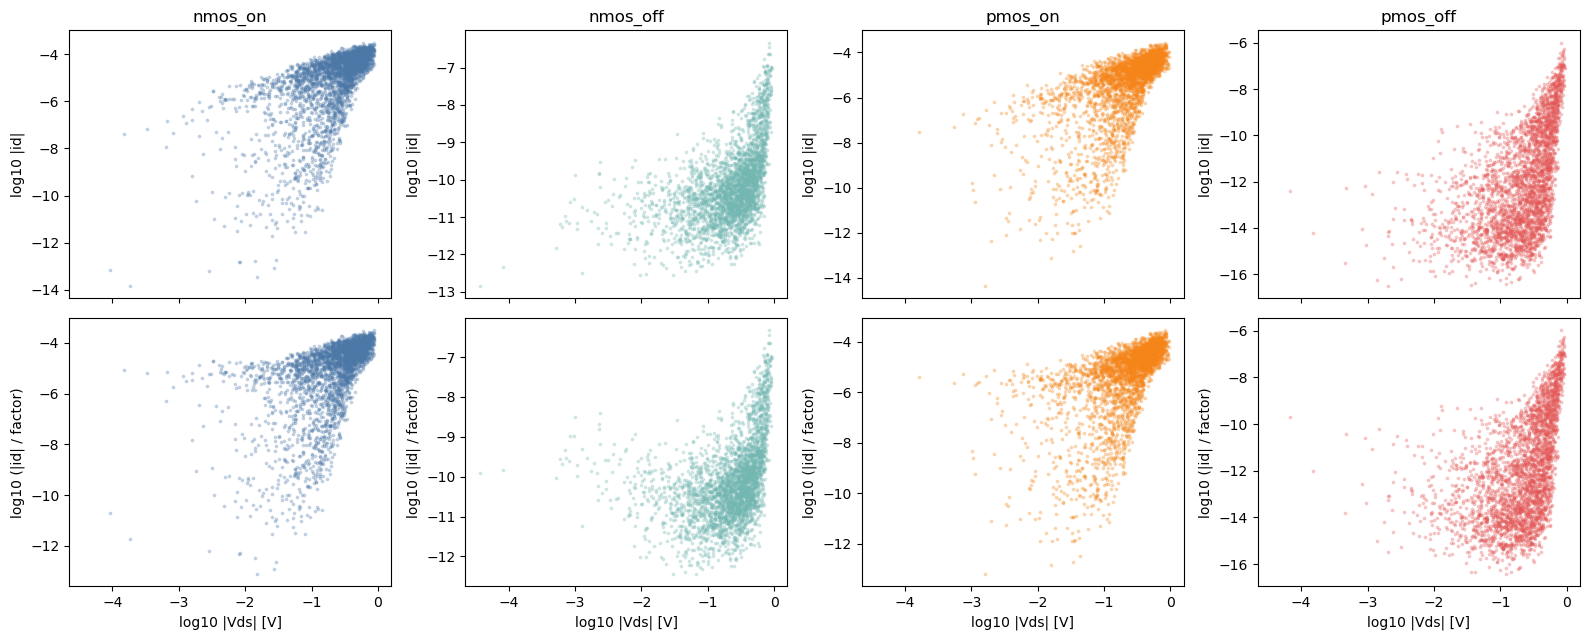

slope of log10|id| vs log10|Vds| for |Vds| < 10 mV (1 = proportional to Vds, 0 = independent of Vds):


,rows_below_10mV,slope_raw,slope_with_factor
case,,,
nmos_on,157,1.241541,0.300257
nmos_off,164,0.376887,-0.597780
pmos_on,173,0.389850,-0.548509
pmos_off,160,-0.205366,-1.160381


In [6]:
fig, ax = plt.subplots(2, 4, figsize=(16, 6.5), sharex=True)
slopes = []
for k, (c, dev) in enumerate(CASES.items()):
    d = canon[c].iloc[splits[c][0]]                      # training rows only: nothing here may depend on validation or test rows
    vds = (d["vd"] - d["vs"]).abs().to_numpy()
    f = vds_factor(vds, d["temp"].to_numpy())
    raw, scaled = np.log10(np.abs(d["id"].to_numpy())), np.log10(np.abs(d["id"].to_numpy()) / f)
    sel = np.random.default_rng(0).choice(len(d), size=3000, replace=False)
    for row, (y, label) in enumerate([(raw, "log10 |id|"), (scaled, "log10 (|id| / factor)")]):
        ax[row, k].scatter(np.log10(vds[sel]), y[sel], s=3, alpha=0.25, color=["#4C78A8", "#72B7B2", "#F58518", "#E45756"][k])
        ax[row, k].set_ylabel(label)
    ax[1, k].set_xlabel("log10 |Vds| [V]")
    ax[0, k].set_title(c)
    small = vds < 10e-3
    slopes.append(dict(case=c, rows_below_10mV=int(small.sum()),
                       slope_raw=np.polyfit(np.log10(vds[small]), raw[small], 1)[0],
                       slope_with_factor=np.polyfit(np.log10(vds[small]), scaled[small], 1)[0]))
fig.tight_layout()
fig.savefig(RESULT_DIR / "vds_aware_target.png", dpi=110)
plt.show()
print("slope of log10|id| vs log10|Vds| for |Vds| < 10 mV (1 = proportional to Vds, 0 = independent of Vds):")
pd.DataFrame(slopes).set_index("case")

Reading the slopes (training rows only; about 160 rows per case lie below 10 mV and all other inputs vary freely, so the numbers are rough and noisy): in NMOS ON the current goes from proportional to Vds (1.24) to nearly independent of it (0.30) with the factor. In the other three cases the raw slope is weak (0.38, 0.39 and -0.21) and the factor over-corrects it (-0.60, -0.55 and -1.16), which for the OFF cases fits the Vds-independent components of the OFF-state `id`. The slopes alone are too noisy to decide the ON cases, so the Vds-aware target is a per-case option chosen on the validation rows (section 10).

## 4. Features
Raw inputs plus quantities built from the known device physics (source-referenced voltages; for PMOS the sign is mirrored so both device types see the same regime):
`q/kT`, `Vgs`, `Vds`, `Vbs`, `Vgd`, the overdrive `(Vgs - Vth)/vT`, `Vds/vT` and `ln W`. Models are free to use either set; the comparison will show which helps.

In [7]:
def make_features(d, device):
    sgn = 1.0 if device == "nmos" else -1.0
    vt = KB_Q * (d["temp"] + 273.15)
    vgs, vds, vbs, vgd = sgn * (d["vg"] - d["vs"]), sgn * (d["vd"] - d["vs"]), sgn * (d["vb"] - d["vs"]), sgn * (d["vg"] - d["vd"])
    X = d[FEATS].copy()
    X["inv_vt"] = 1.0 / vt
    X["vgs"], X["vds"], X["vbs"], X["vgd"] = vgs, vds, vbs, vgd
    X["vov_vt"] = (vgs - sgn * d["vth0"]) / vt          # (Vgs - Vth)/vT; sgn*vth0 is the threshold magnitude for both types
    X["vds_vt"] = vds / vt
    X["log_w"] = np.log(d["w"])
    return X


X_nmos = make_features(canon["nmos_on"], "nmos")
X_pmos = make_features(canon["pmos_on"], "pmos")
print(f"{X_nmos.shape[1]} features per row:", list(X_nmos.columns))
print("Vds >= 0 after canonicalisation (NMOS, PMOS):", bool((X_nmos["vds"] >= 0).all()), bool((X_pmos["vds"] >= 0).all()))
X_nmos.describe().T[["min", "max"]]

20 features per row: ['vdd', 'temp', 'w', 'vd', 'vs', 'vg', 'vb', 'vth0', 'toxe', 'ndep', 'u0', 'xj', 'inv_vt', 'vgs', 'vds', 'vbs', 'vgd', 'vov_vt', 'vds_vt', 'log_w']
Vds >= 0 after canonicalisation (NMOS, PMOS): True True


,min,max
vdd,8.100015e-01,9.899901e-01
temp,-3.997698e+01,1.249639e+02
w,1.604659e-08,1.279977e-07
vd,8.020292e-03,9.858975e-01
vs,4.262181e-06,9.459957e-01
vg,8.100015e-01,9.899901e-01
vb,0.000000e+00,0.000000e+00
vth0,4.316953e-01,5.276100e-01
toxe,8.550239e-10,1.044929e-09
ndep,6.300173e+18,7.699886e+18


## 5. Metrics
Every model is scored the same way, per terminal:
* **R2** on the signed-log target (the scale the models are trained on) and on the linear current,
* **median** and **95th-percentile relative error** `|pred - true| / |true|` (the project text does not define "error"; this is the definition used everywhere in this work), on rows with `|true| >= 1e-15 A`. Below 1e-15 A the currents are at the level of the solver floor (the Kirchhoff residual of the data is up to 1.5e-15 A) and a relative error means nothing, and such currents are negligible next to gate leakages, which are of the order of 1e-10 A or more. The share of rows left out is reported with every table (`frac_below_floor`; it is large only for `ib` and PMOS-OFF `ig`),
* the same errors restricted to the **small-Vds region** (`|Vds| < 5 mV`), where the gate-level ON devices operate.

In [8]:
def score(true, pred, vds):
    """Per-terminal metrics; true and pred are (n, 4) currents in the order id, ig, is, ib."""
    true, pred, vds = np.asarray(true), np.asarray(pred), np.asarray(vds)
    rows = []
    for k, t in enumerate(TERMS):
        yt, yp = np.arcsinh(true[:, k] / I0), np.arcsinh(pred[:, k] / I0)
        r2_log = 1 - ((yt - yp) ** 2).sum() / ((yt - yt.mean()) ** 2).sum()
        r2_lin = 1 - ((true[:, k] - pred[:, k]) ** 2).sum() / ((true[:, k] - true[:, k].mean()) ** 2).sum()
        m = np.abs(true[:, k]) >= REL_FLOOR
        rel = np.abs(pred[m, k] - true[m, k]) / np.abs(true[m, k])
        ms = m & (vds < SMALL_VDS)
        rel_s = np.abs(pred[ms, k] - true[ms, k]) / np.abs(true[ms, k])
        rows.append(dict(terminal=t, r2_log=r2_log, r2_lin=r2_lin, median_rel=np.median(rel), p95_rel=np.percentile(rel, 95), n_used=int(m.sum()), frac_below_floor=float(1 - m.mean()),
                         median_rel_small_vds=np.median(rel_s) if len(rel_s) else np.nan,
                         p95_rel_small_vds=np.percentile(rel_s, 95) if len(rel_s) else np.nan, n_small_vds=int(ms.sum())))
    return pd.DataFrame(rows).set_index("terminal")


# the metrics must behave on known inputs: a perfect prediction scores 0 error, a +1 % prediction scores exactly 1 %
va_idx = splits["nmos_on"][1]
d = canon["nmos_on"].iloc[va_idx]
true = d[TERMS].to_numpy()
vds = (d["vd"] - d["vs"]).abs().to_numpy()
perfect, off_by_1pct = score(true, true, vds), score(true, true * 1.01, vds)
print("perfect prediction: max median error =", perfect["median_rel"].max(), "| R2 (log) =", perfect["r2_log"].min())
print("+1 % prediction:   median error =", off_by_1pct["median_rel"].round(6).tolist(), "(expected 0.01)")
off_by_1pct

perfect prediction: max median error = 0.0 | R2 (log) = 1.0
+1 % prediction:   median error = [0.01, 0.01, 0.01, 0.01] (expected 0.01)


,r2_log,r2_lin,median_rel,p95_rel,n_used,frac_below_floor,median_rel_small_vds,p95_rel_small_vds,n_small_vds
terminal,,,,,,,,,
id,0.999993,0.999839,0.01,0.01,1500,0.000000,0.01,0.01,19
ig,0.999983,0.999891,0.01,0.01,1500,0.000000,0.01,0.01,19
is,0.999993,0.999839,0.01,0.01,1500,0.000000,0.01,0.01,19
ib,0.999990,0.999898,0.01,0.01,1493,0.004667,0.01,0.01,19


## Summary of the harness
* 70/15/15 split with a fixed seed, identical for every model.
* Canonicalisation to Vds >= 0 (NMOS) / Vsd >= 0 (PMOS) fixes the signs of all four currents in the ON cases; in the OFF cases `is`, `ib` and (PMOS) `ig` still change sign, so the signed-log target stays. The SPICE check shows the device is symmetric in D/S (worst mismatch 1.4e-3, usually far smaller).
* Targets: signed log, optionally with the Vds-aware factor for `id` and `is` (round trip exact to floating-point precision). The log-log slopes are too noisy (about 160 rows below 10 mV) to decide where it helps, so it is a per-case option chosen on the validation rows.
* Features: raw inputs plus physics-based ones.
* Metrics: R2 and relative errors per terminal, plus the small-Vds region and the share of rows below the 1e-15 A floor, validated on known inputs.
* Everything that guides a design choice (slopes, signs) is computed on the training rows only; the test rows are not used until part 4.

## 6. Model-ready data
A model sees one **option set**: `vds_aware` (target transform of section 3 on or off) and `physics` (the 8 extra features of section 4 on or off). `prepare` builds the standardised inputs and targets for one case and one option set. The scalers are fitted on the **training rows only**, so nothing from the validation or test rows leaks into the models.

Every model is fitted on the training rows. The validation rows are used to pick the option set and, for gradient boosting, the number of trees. The **test rows are not touched in this part**; they are used once in part 4.

In [9]:
from sklearn.preprocessing import PolynomialFeatures, StandardScaler


def prepare(case, vds_aware, physics):
    """Standardised inputs X and targets Y for one case and one option set (scalers fitted on the training rows)."""
    d = canon[case]
    X = make_features(d, CASES[case])
    if not physics:
        X = X[FEATS]
    vds = (d["vd"] - d["vs"]).abs().to_numpy()
    temp = d["temp"].to_numpy()
    cur = d[TERMS].to_numpy()
    y = encode(cur, vds, temp, vds_aware)
    tr, va, te = splits[case]
    sx, sy = StandardScaler().fit(X.iloc[tr]), StandardScaler().fit(y[tr])
    return dict(case=case, vds_aware=vds_aware, physics=physics, X=sx.transform(X), Y=sy.transform(y), sx=sx, sy=sy,
                vds=vds, temp=temp, cur=cur, tr=tr, va=va, te=te, columns=list(X.columns))


def to_currents(P, prep, idx):
    """Standardised model output for the rows idx -> currents (n, 4) in A (canonical orientation)."""
    return decode(prep["sy"].inverse_transform(P), prep["vds"][idx], prep["temp"][idx], prep["vds_aware"])


# checks: scalers are fitted on the training rows, and the standardised targets decode back to the SPICE currents
for aware in (False, True):
    p = prepare("nmos_on", aware, True)
    back = to_currents(p["Y"][p["va"]], p, p["va"])
    m = np.abs(p["cur"][p["va"]]) > 0
    err = np.max(np.abs(back[m] - p["cur"][p["va"]][m]) / np.abs(p["cur"][p["va"]][m]))
    print(f"vds_aware={aware}: train mean {p['X'][p['tr']].mean():+.1e}, train std {p['X'][p['tr']].std(axis=0).mean():.3f}, "
          f"{p['X'].shape[1]} features, decode round trip max rel. error {err:.1e}")

vds_aware=False: train mean +4.1e-16, train std 0.950, 20 features, decode round trip max rel. error 2.0e-15
vds_aware=True: train mean +4.1e-16, train std 0.950, 20 features, decode round trip max rel. error 2.6e-15


## 7. Selection rule and common interface
All model families share one interface (`fit(X, Y, X_val, Y_val)` and `predict(X)` on standardised arrays), so the neural models of part 3 can be added to the same table.

**Selection rule (validation rows only):** the option set and settings with the lowest **mean over the four terminals of the median relative error** (|I| >= 1e-15 A). The median error is the closest of the metrics to the 1 % goal of the project; the 95th percentile and the R2 of the signed-log currents are reported next to it, and the table below also checks whether R2 would have chosen differently.

In [10]:
from sklearn.linear_model import RidgeCV
import lightgbm as lgb
import time

RIDGE_ALPHAS = np.logspace(-6, 3, 19)
MODEL_SEED = 0                              # seed of every model fit in this notebook (the data split uses SPLIT_SEED)


class PolyRidge:
    """Polynomial features of the standardised inputs + ridge regression; the penalty is chosen per terminal by
    leave-one-out cross-validation on the training rows (no validation rows involved)."""

    def __init__(self, degree):
        self.degree = degree

    def fit(self, X, Y, X_val=None, Y_val=None):
        self.poly = PolynomialFeatures(self.degree, include_bias=False)
        self.ridge = RidgeCV(alphas=RIDGE_ALPHAS, alpha_per_target=True).fit(self.poly.fit_transform(X), Y)
        self.setting = f"degree={self.degree}, alpha={[float(f'{a:.3g}') for a in self.ridge.alpha_]}"
        return self

    def predict(self, X):
        return self.ridge.predict(self.poly.transform(X))


class GradientBoosting:
    """One LightGBM regressor per terminal; early stopping on the validation rows chooses the number of trees."""

    def __init__(self, max_trees=3000, learning_rate=0.05):
        self.max_trees, self.learning_rate = max_trees, learning_rate

    def fit(self, X, Y, X_val, Y_val):
        self.models = []
        for k in range(Y.shape[1]):
            m = lgb.LGBMRegressor(n_estimators=self.max_trees, learning_rate=self.learning_rate, num_leaves=31, min_child_samples=10,
                                  subsample=0.8, subsample_freq=1, colsample_bytree=0.9, random_state=MODEL_SEED, deterministic=True,
                                  force_row_wise=True, n_jobs=8, verbosity=-1)
            m.fit(X, Y[:, k], eval_set=[(X_val, Y_val[:, k])], callbacks=[lgb.early_stopping(100, verbose=False)])
            self.models.append(m)
        self.setting = f"trees={[m.best_iteration_ for m in self.models]}"
        return self

    def predict(self, X):
        return np.column_stack([m.predict(X) for m in self.models])


def evaluate(model, prep, family):
    """Validation-set metrics of a fitted model, one row of the comparison table."""
    va = prep["va"]
    s = score(prep["cur"][va], to_currents(model.predict(prep["X"][va]), prep, va), prep["vds"][va])
    row = dict(case=prep["case"], family=family, vds_aware=prep["vds_aware"], physics=prep["physics"], setting=model.setting,
               r2_log=s["r2_log"].mean(), r2_lin=s["r2_lin"].mean(), median_rel=s["median_rel"].mean(), p95_rel=s["p95_rel"].mean(),
               median_rel_small_vds=s["median_rel_small_vds"].mean())
    metrics = ("r2_log", "r2_lin", "median_rel", "p95_rel", "median_rel_small_vds", "n_small_vds", "n_used", "frac_below_floor")
    row.update({f"{m}_{t}": s.loc[t, m] for t in TERMS for m in metrics})      # all metrics per terminal
    return row


OPTIONS = [(a, p) for a in (False, True) for p in (False, True)]
prep_cache = {(c, a, p): prepare(c, a, p) for c in CASES for a, p in OPTIONS}
rows, best = [], {}       # best[(case, family)] = (median_rel, fitted model, option set)


def run(family, case, vds_aware, physics, model):
    prep = prep_cache[(case, vds_aware, physics)]
    model.fit(prep["X"][prep["tr"]], prep["Y"][prep["tr"]], prep["X"][prep["va"]], prep["Y"][prep["va"]])
    row = evaluate(model, prep, family)
    rows.append(row)
    key = (case, family)
    if key not in best or row["median_rel"] < best[key][0]:
        best[key] = (row["median_rel"], model, (vds_aware, physics))
    return row

## 8. Polynomial ridge regression
Degrees 2, 3 and 4 on the 12 raw inputs and degrees 2 and 3 on the 20 physics features, for every option set and case. Degree 4 on the 20 physics features would have more than 10,000 terms (a 7,000 x 10,625 matrix, about 600 MB), so the number of terms is capped at about 1,800 per model. The ridge penalty is chosen per terminal by leave-one-out cross-validation on the training rows.

In [11]:
t0 = time.time()
for case in CASES:
    for aware, physics in OPTIONS:
        for degree in ((2, 3) if physics else (2, 3, 4)):
            run("poly", case, aware, physics, PolyRidge(degree))
        print(f"  {case} vds_aware={aware} physics={physics}: {time.time() - t0:.0f} s")
poly_table = pd.DataFrame(rows)
poly_table.groupby(["case", "vds_aware", "physics"])["median_rel"].min().unstack(["vds_aware", "physics"]).round(3)

  nmos_on vds_aware=False physics=False: 8 s


  nmos_on vds_aware=False physics=True: 16 s


  nmos_on vds_aware=True physics=False: 25 s


  nmos_on vds_aware=True physics=True: 32 s


  nmos_off vds_aware=False physics=False: 39 s


  nmos_off vds_aware=False physics=True: 47 s


... (7 outputs left out)

  pmos_off vds_aware=False physics=True: 114 s


  pmos_off vds_aware=True physics=False: 123 s


  pmos_off vds_aware=True physics=True: 131 s


vds_aware  False         True        
physics    False  True   False  True 
case                                 
nmos_off   0.349  0.336  0.362  0.342
nmos_on    0.107  0.127  0.073  0.112
pmos_off   0.347  0.318  0.350  0.314
pmos_on    0.108  0.123  0.080  0.101

## 9. Gradient boosting (LightGBM)
One regressor per terminal, 31 leaves, learning rate 0.05, up to 3,000 trees with early stopping on the validation rows. `deterministic=True` and a fixed seed make the fit repeatable, which is checked first. The number of trees is chosen on the validation rows, so the validation errors of this family are slightly optimistic (the polynomial penalty is chosen by cross-validation on the training rows and has no such effect); the test rows in part 4 give the unbiased numbers.

In [12]:
# repeatability: the same fit twice must give identical predictions
prep = prep_cache[("nmos_on", True, True)]
p1 = GradientBoosting(max_trees=200).fit(prep["X"][prep["tr"]], prep["Y"][prep["tr"]], prep["X"][prep["va"]], prep["Y"][prep["va"]]).predict(prep["X"][prep["va"]])
p2 = GradientBoosting(max_trees=200).fit(prep["X"][prep["tr"]], prep["Y"][prep["tr"]], prep["X"][prep["va"]], prep["Y"][prep["va"]]).predict(prep["X"][prep["va"]])
print("two identical fits give identical predictions:", bool(np.array_equal(p1, p2)))

two identical fits give identical predictions: True


In [13]:
t0 = time.time()
for case in CASES:
    for aware, physics in OPTIONS:
        run("lightgbm", case, aware, physics, GradientBoosting())
    print(f"{case}: done after {time.time() - t0:.0f} s")
baselines = pd.DataFrame(rows)
baselines.to_csv(RESULT_DIR / "baselines_validation.csv", index=False)
baselines[baselines.family == "lightgbm"].groupby(["case", "vds_aware", "physics"])["median_rel"].min().unstack(["vds_aware", "physics"]).round(3)

nmos_on: done after 53 s


nmos_off: done after 95 s


pmos_on: done after 147 s


pmos_off: done after 169 s


vds_aware  False         True        
physics    False  True   False  True 
case                                 
nmos_off   0.122  0.087  0.149  0.092
nmos_on    0.098  0.061  0.090  0.059
pmos_off   0.170  0.102  0.177  0.108
pmos_on    0.098  0.074  0.093  0.074

## 10. Baseline comparison (validation rows)
Best option set and settings of each family and case by the selection rule, with the median relative error per terminal. The last column says whether the R2 of the signed-log currents would have picked the same option set.

In [14]:
pick = baselines.loc[baselines.groupby(["case", "family"])["median_rel"].idxmin()].set_index(["case", "family"])
pick_r2 = baselines.loc[baselines.groupby(["case", "family"])["r2_log"].idxmax()].set_index(["case", "family"])
pick["same_choice_by_r2"] = [(pick.loc[k, "vds_aware"], pick.loc[k, "physics"]) == (pick_r2.loc[k, "vds_aware"], pick_r2.loc[k, "physics"]) for k in pick.index]
shown = pick[["vds_aware", "physics", "median_rel", "p95_rel", "r2_log", "median_rel_id", "median_rel_ig", "median_rel_is", "median_rel_ib", "same_choice_by_r2", "setting"]]
shown.round({"median_rel": 4, "p95_rel": 3, "r2_log": 4, "median_rel_id": 4, "median_rel_ig": 4, "median_rel_is": 4, "median_rel_ib": 4})

vds_aware  physics  median_rel  p95_rel  r2_log  median_rel_id  median_rel_ig  median_rel_is  median_rel_ib  same_choice_by_r2                                        setting
case     family                                                                                                                                                                                 
nmos_off lightgbm      False     True      0.0874    0.433  0.9913         0.0622         0.0397         0.2180         0.0299               True                  trees=[3000, 2093, 432, 2593]
         poly          False     True      0.3358   10.899  0.9605         0.2501         0.0225         0.9993         0.0712              False    degree=3, alpha=[31.6, 3.16, 100.0, 0.0001]
nmos_on  lightgbm       True     True      0.0592    0.272  0.9981         0.0412         0.0545         0.0397         0.1016               True                 trees=[1364, 2996, 2982, 3000]
         poly           True    False      0.0733    0.284  0.9977         0.0762         0.0509         0.0667         0.0994               True       degree=4, alpha=[1.0, 0.316, 0.316, 1.0]
pmos_off lightgbm      False     True      0.1016    0.451  0.9786         0.1133         0.0846         0.1727         0.0360              False                   trees=[2132, 107, 1275, 244]
         poly           True     True      0.3136    1.925  0.9643         0.3539         0.0884         0.7258         0.0863              False  degree=3, alpha=[0.000316, 31.6, 1.0, 0.0001]
pmos_on  lightgbm      False     True      0.0738    0.292  0.9980         0.0440         0.0979         0.0558         0.0977              False                  trees=[2876, 2999, 368, 3000]
         poly           True    False      0.0802    0.281  0.9981         0.0657         0.0728         0.0892         0.0930               True     degree=4, alpha=[1e-06, 0.316, 1.0, 0.316]

### Format of deliverable 4 and the rows left out of the relative errors
The comparison table asked for by the project has one row per case and, per model type, R2, median error and 95th-percentile error on the validation rows. Here is the part of it that exists so far (two of the four model types; each value is the mean over the four terminals; R2 is on the signed-log currents). Part 3 completes it.
Relative errors leave out the rows with `|I| < 1e-15 A`; their share depends only on the data and is listed below.

In [15]:
table4 = pick[["r2_log", "median_rel", "p95_rel"]].unstack("family").swaplevel(axis=1).sort_index(axis=1)
display(table4.round(4))
floor_share = pd.DataFrame({c: {t: baselines.loc[baselines.case == c, f"frac_below_floor_{t}"].iloc[0] for t in TERMS} for c in CASES}).T
print("share of the validation rows left out of the relative errors (|I| < 1e-15 A), in %:")
(floor_share * 100).round(1)

family     lightgbm                       poly                 
         median_rel p95_rel  r2_log median_rel  p95_rel  r2_log
case                                                           
nmos_off     0.0874  0.4329  0.9913     0.3358  10.8990  0.9605
nmos_on      0.0592  0.2724  0.9981     0.0733   0.2837  0.9977
pmos_off     0.1016  0.4508  0.9786     0.3136   1.9249  0.9643
pmos_on      0.0738  0.2922  0.9980     0.0802   0.2807  0.9981

share of the validation rows left out of the relative errors (|I| < 1e-15 A), in %:


,id,ig,is,ib
nmos_on,0.0,0.0,0.0,0.5
nmos_off,0.0,0.0,0.0,57.7
pmos_on,0.0,1.1,0.0,1.0
pmos_off,5.7,36.8,10.7,57.7


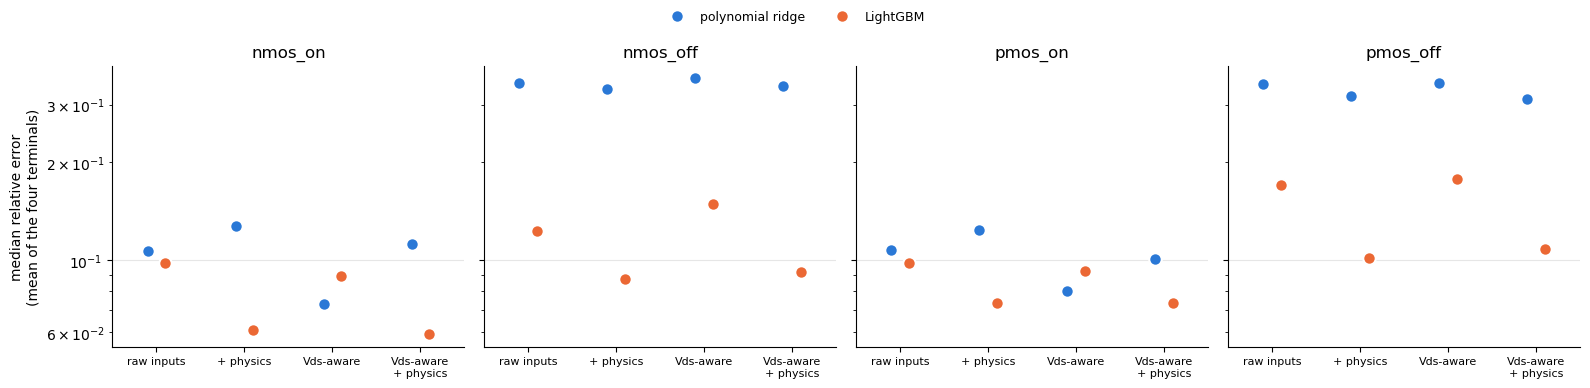

In [16]:
# effect of the two options: best median error of each family for each option set (log scale; lower is better)
COL = {"poly": "#2a78d6", "lightgbm": "#eb6834"}
LABEL = {"poly": "polynomial ridge", "lightgbm": "LightGBM"}
labels = ["raw inputs", "+ physics", "Vds-aware", "Vds-aware\n+ physics"]
fig, ax = plt.subplots(1, 4, figsize=(16, 3.9), sharey=True)
for a, case in zip(ax, CASES):
    for fam, dx in (("poly", -0.1), ("lightgbm", 0.1)):
        vals = [baselines[(baselines.case == case) & (baselines.family == fam) & (baselines.vds_aware == aw) & (baselines.physics == ph)]["median_rel"].min()
                for aw, ph in OPTIONS]
        a.plot(np.arange(4) + dx, vals, "o", ms=9, color=COL[fam], mec="white", mew=1.5, label=LABEL[fam])
    a.set_yscale("log"); a.set_title(case); a.set_xticks(range(4)); a.set_xticklabels(labels, fontsize=8); a.set_xlim(-0.5, 3.5)
    a.grid(axis="y", color="0.9", lw=0.8); a.set_axisbelow(True)
    a.spines[["top", "right"]].set_visible(False)
ax[0].set_ylabel("median relative error\n(mean of the four terminals)")
handles, names = ax[0].get_legend_handles_labels()
fig.legend(handles, names, loc="upper center", ncol=2, frameon=False, fontsize=9)
fig.tight_layout(rect=(0, 0, 1, 0.93))
fig.savefig(RESULT_DIR / "baseline_options.png", dpi=110)
plt.show()

## Summary of the baselines
Validation rows only (median relative error, mean of the four terminals; the test rows have not been used):

| case | LightGBM | polynomial ridge |
|---|---|---|
| NMOS ON | 5.9 % | 7.3 % |
| NMOS OFF | 8.7 % | 33.6 % |
| PMOS ON | 7.4 % | 8.0 % |
| PMOS OFF | 10.2 % | 31.4 % |

* **Physics features** help LightGBM in every case (for example NMOS OFF 12.2 % -> 8.7 %, PMOS OFF 17.0 % -> 10.2 %, NMOS ON 9.8 % -> 6.1 %). For polynomial ridge they help only the OFF cases; in the ON cases the physics-feature polynomials are limited to degree 3 by the term cap, so that comparison is not like for like.
* **The Vds-aware target** helps the ON cases, clearly for polynomial ridge (NMOS ON 10.7 % -> 7.3 %, PMOS ON 10.8 % -> 8.0 %) and slightly for LightGBM, and **hurts the OFF cases** for both families (LightGBM with physics features: NMOS OFF 8.7 % -> 9.2 %, PMOS OFF 10.2 % -> 10.8 %). The OFF-case result fits the explanation in section 3 (the OFF-state `id` has Vds-independent components); the slopes there are too noisy to decide the ON cases, which the validation rows do.
* **Polynomials cannot follow the OFF currents**, which span many decades (31-34 % median error, and about 100 % for `is` in NMOS OFF).
* The hardest terminal is `is` in the OFF cases (LightGBM: 21.8 % NMOS OFF, 17.3 % PMOS OFF); in the ON cases it is `ib` (about 10 %).
* No baseline is near the 1 % goal (best: 5.9 %), so the neural models of part 3 are needed.
* LightGBM reached the 3,000-tree cap for several terminals, so those fits are not fully converged; it was not tuned further because it is a baseline.
* For 4 of the 8 family and case pairs, picking by R2 of the signed-log currents instead of the median error would choose a different option set (column `same_choice_by_r2`); the selection rule stays the median error.

Next: the plain MLP and the residual MLP on the same data, and the full comparison table.